# Домашнее задание 1

**ФИО:** Аристеев Олег Алексеевич

In [2]:
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("svg")

## 1. Загрузка и описание данных

Начнем с загрузки необходимых данных;

Был выбран Amazon Reviews dataset, 2023, раздел - Video Games

Его описание лежит на [сайте](https://amazon-reviews-2023.github.io/#) и в файле DATA.md текущей директории

Рекомендуем товары категории Video Games. Взаимодействием является отзыв пользователя.

Релевантным считаем новый для него товар с будущей оценкой 4–5.

In [3]:
from pathlib import Path
from urllib.request import urlretrieve

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

base = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw"
urls = {
    "Video_Games.jsonl.gz": f"{base}/review_categories/Video_Games.jsonl.gz",
    "meta_Video_Games.jsonl.gz": f"{base}/meta_categories/meta_Video_Games.jsonl.gz",
}

for name, url in urls.items():
    path = data_dir / name
    if not path.exists():
        temp = path.with_suffix(".gz.part")
        urlretrieve(url, temp)
        temp.replace(path)
    print(f"{name}: {path.stat().st_size / 1024**2:.1f} МиБ")

reviews_path = data_dir / "Video_Games.jsonl.gz"
meta_path = data_dir / "meta_Video_Games.jsonl.gz"

Video_Games.jsonl.gz: 776.5 МиБ
meta_Video_Games.jsonl.gz: 98.3 МиБ


In [4]:
import gzip
import json

for path in (reviews_path, meta_path):
    with gzip.open(path, "rt", encoding="utf-8") as f:
        record = json.loads(next(f))
    print(f"{path.name}:")
    for r in list(record):
        print(f"   -{r}")
    print()

Video_Games.jsonl.gz:
   -rating
   -title
   -text
   -images
   -asin
   -parent_asin
   -user_id
   -timestamp
   -helpful_vote
   -verified_purchase

meta_Video_Games.jsonl.gz:
   -main_category
   -title
   -average_rating
   -rating_number
   -features
   -description
   -price
   -images
   -videos
   -store
   -categories
   -details
   -parent_asin
   -bought_together



In [5]:
import pandas as pd

reviews = pd.read_json(reviews_path, lines=True)
items = pd.read_json(meta_path, lines=True)


In [6]:
reviews.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4,It’s pretty sexual. Not my fav,I’m playing on ps5 and it’s interesting. It’s...,[],B07DJWBYKP,B07DK1H3H5,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,2020-12-17 06:33:24.795,0,True
1,5,Good. A bit slow,Nostalgic fun. A bit slow. I hope they don’t...,[],B00ZS80PC2,B07SRWRH5D,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,2020-04-16 15:31:54.941,1,False
2,5,... an order for my kids & they have really en...,This was an order for my kids & they have real...,[],B01FEHJYUU,B07MFMFW34,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,2017-03-30 12:37:11.000,0,True
3,5,Great alt to pro controller,"These work great, They use batteries which is ...",[],B07GXJHRVK,B0BCHWZX95,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,2019-12-29 16:40:34.017,0,True
4,5,solid product,I would recommend to anyone looking to add jus...,[],B00HUWA45W,B00HUWA45W,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,2015-03-29 01:18:52.000,0,True


Описание столбцов:

- `rating` - оценка пользователя от 1 до 5
- `title` - заголовок отзыва
- `text` - текст отзыва
- `images` - прикрепленные пользователем изображения
- `asin` - идентификатор конкретного варианта товара на Amazon
- `parent_asin` - общий идентификатор товара для связи с метаданными, который объединяет варианты одного товара
- `user_id` - идентификатор автора отзыва
- `timestamp` - время публикации отзыва
- `helpful_vote` - сколько голосово "Полезно" получил отзыв
- `verified_purchase` - подтвердил ли Amazon покупку автором отзыва


In [7]:
items.head()

,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
0,Video Games,Dash 8-300 Professional Add-On,5.0,1,[Features Dash 8-300 and 8-Q300 ('Q' rollout l...,[The Dash 8-300 Professional Add-On lets you p...,None,[{'thumb': 'https://m.media-amazon.com/images/...,[],Aerosoft,"[Video Games, PC, Games]",{'Pricing': 'The strikethrough price is the Li...,B000FH0MHO,NaN,NaN,NaN
1,Video Games,Phantasmagoria: A Puzzle of Flesh,4.1,18,[Windows 95],[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[],Sierra,"[Video Games, PC, Games]","{'Best Sellers Rank': {'Video Games': 137612, ...",B00069EVOG,NaN,NaN,NaN
2,Video Games,NBA 2K17 - Early Tip Off Edition - PlayStation 4,4.3,223,[The #1 rated NBA video game simulation series...,[Following the record-breaking launch of NBA 2...,58.0,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'NBA 2K17 - Kobe: Haters vs Players...,2K,"[Video Games, PlayStation 4, Games]","{'Release date': 'September 16, 2016', 'Best S...",B00Z9TLVK0,NaN,NaN,NaN
3,Video Games,Nintendo Selects: The Legend of Zelda Ocarina ...,4.9,22,[Authentic Nintendo Selects: The Legend of Zel...,[],37.42,[{'thumb': 'https://m.media-amazon.com/images/...,[],Amazon Renewed,"[Video Games, Legacy Systems, Nintendo Systems...","{'Best Sellers Rank': {'Video Games': 51019, '...",B07SZJZV88,NaN,NaN,NaN
4,Video Games,Thrustmaster Elite Fitness Pack for Nintendo Wii,3.0,3,"[Includes (9) Total Accessories, Pedometer, Wi...",[The Thrustmaster Motion Plus Elite Fitness Pa...,None,[{'thumb': 'https://m.media-amazon.com/images/...,[],THRUSTMASTER,"[Video Games, Legacy Systems, Nintendo Systems...","{'Release date': 'November 1, 2009', 'Pricing'...",B002WH4ZJG,NaN,NaN,NaN


Описание столбцов:
- `main_category` - основная категория товара
- `title` - название товара
- `average_rating` - рейтинг товара на странице товара
- `rating_number` - количество оценок на странице товара
- `features` - список характеристик товара
- `description` - описание, представленное списком текстовых фрагментов
- `price` - цена в долларах на момент сбора данных
- `images` - изображения товара и ссылки на них
- `videos` - видеоматериалы товара
- `store` - название магазига
- `categories` - иерархия категорий
- `details` - словарь дополнительных характеристик: бренд, размеры и прочее
- `parent_asin` - общий идентификатор товара для связи с метаданными
- `bought_together` - рекомендуемые на сайте комплекты товаров
- `subtitle` - ??? 
- `author` - ???

## 2. EDA и подготовка данных

### 2.1 Обзор отзывов

In [8]:
display(pd.Series({
    "Отзывов": len(reviews),
    "Пользователей": reviews["user_id"].nunique(),
    "Товаров в отзывах": reviews["parent_asin"].nunique(),
    "Строк метаданных": len(items),
    "Товаров в метаданных": items["parent_asin"].nunique(),
    "Первый отзыв": reviews["timestamp"].min(),
    "Последний отзыв": reviews["timestamp"].max(),
}))

Отзывов                                    4624615
Пользователей                              2766656
Товаров в отзывах                           137249
Строк метаданных                            137269
Товаров в метаданных                        137269
Первый отзыв                   1998-11-17 19:58:49
Последний отзыв         2023-09-12 09:02:35.529000
dtype: object

In [9]:
display(reviews.isna().sum().rename("Пропуски в отзывах"))
display(items.isna().sum().rename("Пропуски в метаданных"))

rating               0
title                0
text                 0
images               0
asin                 0
parent_asin          0
user_id              0
timestamp            0
helpful_vote         0
verified_purchase    0
Name: Пропуски в отзывах, dtype: int64

main_category       11035
title                   0
average_rating          0
rating_number           0
features                0
description             0
price               75261
images                  0
videos                  0
store                4361
categories              0
details                 0
parent_asin             0
bought_together    137269
subtitle           136919
author             137007
Name: Пропуски в метаданных, dtype: int64

### 2.2 Обзор товаров

In [10]:
display(pd.Series({
    "Повторы user–item": reviews.duplicated(["user_id", "parent_asin"]).sum(),
    "Отзывов без карточки": (~reviews["parent_asin"].isin(items["parent_asin"])).sum(),
    "Товаров без карточки": (
        ~reviews["parent_asin"].drop_duplicates().isin(items["parent_asin"])
    ).sum(),
}))

Повторы user–item       69115
Отзывов без карточки        0
Товаров без карточки        0
dtype: int64

In [11]:
repeated = reviews.duplicated(["user_id", "parent_asin"], keep=False)

display(
    reviews.loc[repeated, ["user_id", "parent_asin", "asin", "rating", "timestamp"]]
    .sort_values(["user_id", "parent_asin", "timestamp"])
    .head(10)
)

,user_id,parent_asin,asin,rating,timestamp
134649,AE22ALRPU3AXU73ZI7JQAGJAPKRQ,B009VUHVPM,B008OSDHFK,5,2012-12-25 19:45:29.000
134648,AE22ALRPU3AXU73ZI7JQAGJAPKRQ,B009VUHVPM,B008OSDEVM,5,2012-12-25 19:46:50.000
3828038,AE22CAI62UFMGSLT2FL6FQ7X4CKA,B097CZXZR1,B08NVV4FTM,1,2021-09-08 13:09:24.139
3828046,AE22CAI62UFMGSLT2FL6FQ7X4CKA,B097CZXZR1,B08NVV4FTM,1,2021-09-08 13:09:24.139
3828047,AE22CAI62UFMGSLT2FL6FQ7X4CKA,B097CZXZR1,B08NVV4FTM,1,2021-09-08 13:09:24.139
3828060,AE22CAI62UFMGSLT2FL6FQ7X4CKA,B097CZXZR1,B08NVV4FTM,1,2021-09-08 13:09:24.139
3857587,AE22CTYILQKMBR4RMJ5F5WM2EYCA,B0883P3VSH,B00YXO5U40,1,2019-01-24 17:54:09.654
3857615,AE22CTYILQKMBR4RMJ5F5WM2EYCA,B0883P3VSH,B00YXO5U40,1,2019-01-24 17:54:09.654
589408,AE22E3XNIF5TITEAJXHT55LD5QUQ,B01MRR7GPX,B01MRR7GPX,2,2017-07-11 12:56:31.456
589409,AE22E3XNIF5TITEAJXHT55LD5QUQ,B01MRR7GPX,B01MRR7GPX,2,2017-07-11 12:56:31.456


In [33]:
item_metadata = items[["parent_asin"]].copy()

item_metadata["category_group"] = items["categories"].map(
    lambda value: value[1]
    if isinstance(value, (list, tuple)) and len(value) > 1
    else pd.NA
)
item_metadata["category_leaf"] = items["categories"].map(
    lambda value: value[-1]
    if isinstance(value, (list, tuple)) and len(value) > 1
    else pd.NA
)

metadata_fields = ["category_group", "category_leaf"]

for field in metadata_fields:
    item_metadata[field] = (
        item_metadata[field].astype("string").str.strip().replace("", pd.NA)
    )

display(pd.DataFrame({
    "Разных значений": item_metadata[metadata_fields].nunique(),
    "Пропусков, %": (
        item_metadata[metadata_fields].isna().mean() * 100
    ).round(2),
}))

display(item_metadata.head())

,Разных значений,"Пропусков, %"
category_group,53,9.21
category_leaf,160,9.21


,parent_asin,category_group,category_leaf
0,B000FH0MHO,PC,Games
1,B00069EVOG,PC,Games
2,B00Z9TLVK0,PlayStation 4,Games
3,B07SZJZV88,Legacy Systems,Games
4,B002WH4ZJG,Legacy Systems,Fitness Accessories


### 2.3 Активность пользователей

In [12]:
pairs = reviews[["user_id", "parent_asin"]].drop_duplicates()

user_counts = pairs["user_id"].value_counts()
item_counts = pairs["parent_asin"].value_counts()

display(pd.DataFrame({
    "Товаров у пользователя": user_counts.describe(percentiles=[.50, .90, .99]),
    "Пользователей у товара": item_counts.describe(percentiles=[.50, .90, .99]),
}))

,Товаров у пользователя,Пользователей у товара
count,2.766656e+06,137249.000000
mean,1.646573e+00,33.191499
std,2.328234e+00,196.969966
min,1.000000e+00,1.000000
50%,1.000000e+00,4.000000
90%,3.000000e+00,50.000000
99%,9.000000e+00,537.000000
max,5.440000e+02,17893.000000


In [13]:
pairs = reviews[["user_id", "parent_asin"]].drop_duplicates()
user_counts = pairs["user_id"].value_counts()
item_counts = pairs["parent_asin"].value_counts()

density = len(pairs) / (len(user_counts) * len(item_counts))

print(f"Пользователей: {len(user_counts):,}")
print(f"Товаров: {len(item_counts):,}")
print(f"Уникальных взаимодействий: {len(pairs):,}")
print(f"Плотность: {density:.10f}")

Пользователей: 2,766,656
Товаров: 137,249
Уникальных взаимодействий: 4,555,500
Плотность: 0.0000119970


In [14]:
ratings = reviews["rating"].value_counts().sort_index()

display(pd.DataFrame({
    "Отзывов": ratings,
    "Доля, %": (ratings / len(reviews) * 100).round(2),
}).rename_axis("Оценка"))

,Отзывов,"Доля, %"
Оценка,,
1,589519,12.75
2,249878,5.40
3,340086,7.35
4,617251,13.35
5,2827881,61.15


### 2.4 Очистка данных

In [15]:
events = reviews[["user_id", "parent_asin", "rating", "timestamp"]].copy()
events["timestamp"] = pd.to_datetime(events["timestamp"], utc=True, errors="coerce")

events = events.dropna()
events = events[
    events["user_id"].str.strip().ne("")
    & events["parent_asin"].str.strip().ne("")
    & events["rating"].isin([1, 2, 3, 4, 5])
]

print(f"Некорректных записей: {len(reviews) - len(events):,}")

n_before = len(events)
events = (
    events.drop_duplicates()
    .sort_values("timestamp", kind="stable")
    .reset_index(drop=True)
)

print(f"Совпадающих событий: {n_before - len(events):,}")
print(f"Осталось событий: {len(events):,}")

Некорректных записей: 0
Совпадающих событий: 53,653
Осталось событий: 4,570,962


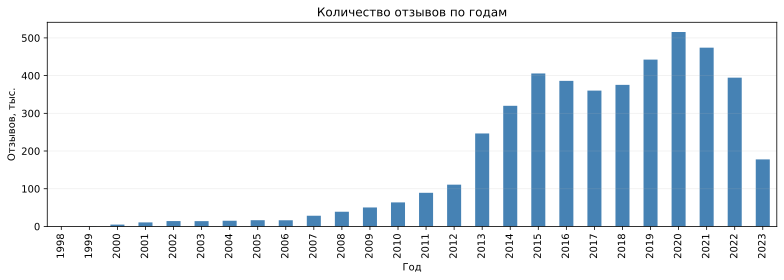

In [16]:
import matplotlib.pyplot as plt

by_year = events.groupby(events["timestamp"].dt.year).size()

ax = (by_year / 1000).plot.bar(figsize=(11, 4), color="steelblue")
ax.set(
    title="Количество отзывов по годам",
    xlabel="Год",
    ylabel="Отзывов, тыс.",
)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

*Замечание*: 2023 год представлен только до сентября

## 3. Протокол оценки

Разобьем наш датасет на части train/validation/test:
- train - всё до 2022 года, 
- validation - 2022 год, 
- test - доступная часть 2023 года

Основная метрика — NDCG@10, дополнительная — Recall@10

In [17]:
valid_start = pd.Timestamp("2022-01-01", tz="UTC")
test_start = pd.Timestamp("2023-01-01", tz="UTC")

train = events[events["timestamp"] < valid_start].copy()
valid = events[
    (events["timestamp"] >= valid_start)
    & (events["timestamp"] < test_start)
].copy()
test = events[events["timestamp"] >= test_start].copy()

In [18]:
counts = train.groupby("user_id")["parent_asin"].nunique()
selected_users = counts.index[counts >= 5]

train = train[train["user_id"].isin(selected_users)].copy()
valid = valid[valid["user_id"].isin(selected_users)].copy()
test = test[test["user_id"].isin(selected_users)].copy()

display(pd.DataFrame([
    [name, len(df), df["user_id"].nunique(), df["parent_asin"].nunique()]
    for name, df in [("Train", train), ("Valid", valid), ("Test", test)]
], columns=["Часть", "Событий", "Пользователей", "Товаров"]))

,Часть,Событий,Пользователей,Товаров
0,Train,870753,98942,70882
1,Valid,23188,11158,9668
2,Test,5880,3708,3762


По train отобраны пользователи с минимум пятью разными товарами. Сохранены их события во всех периодах: 899 821 событие от 98 942 пользователей. 

In [19]:
pair = ["user_id", "parent_asin"]

train_ratings = (
    train.sort_values("timestamp", kind="stable")
    .drop_duplicates(pair, keep="last")
)

print(f"Обучающих пар: {len(train_ratings):,}")

Обучающих пар: 863,109


In [20]:
valid_catalog = pd.Index(train_ratings["parent_asin"].unique())

valid_last = (
    valid.sort_values("timestamp", kind="stable")
    .drop_duplicates(pair, keep="last")
)

known_user = valid_last["user_id"].isin(train_ratings["user_id"])
known_item = valid_last["parent_asin"].isin(valid_catalog)

seen_pairs = pd.MultiIndex.from_frame(train_ratings[pair])
already_seen = pd.MultiIndex.from_frame(valid_last[pair]).isin(seen_pairs)

valid_targets = valid_last[
    known_user
    & known_item
    & ~already_seen
    & valid_last["rating"].ge(4)
].copy()

In [21]:
display(pd.Series({
    "Пар в validation": len(valid_last),
    "Пар с новым пользователем": (~known_user).sum(),
    "Пар с новым товаром": (~known_item).sum(),
    "Ранее оценённых пар": already_seen.sum(),
    "Доступных релевантных пар": len(valid_targets),
    "Пользователей для оценки": valid_targets["user_id"].nunique(),
}))

Пар в validation             23035
Пар с новым пользователем        0
Пар с новым товаром           8592
Ранее оценённых пар             70
Доступных релевантных пар    10749
Пользователей для оценки      6325
dtype: int64

In [22]:
valid_relevant = (
    valid_targets.groupby("user_id")["parent_asin"].agg(set).to_dict()
)

valid_seen = (
    train_ratings[train_ratings["user_id"].isin(valid_relevant)]
    .groupby("user_id")["parent_asin"].agg(set).to_dict()
)

In [23]:
import numpy as np

def evaluate(recommendations, relevant, k=10):
    discounts = 1 / np.log2(np.arange(2, k + 2))
    scores = []

    for user, truth in relevant.items():
        top = recommendations[user][:k]
        if len(top) != len(set(top)):
            raise ValueError(f"Повторы в рекомендациях пользователя {user}")

        hits = np.array([item in truth for item in top], dtype=float)
        recall = hits.sum() / len(truth)
        dcg = hits @ discounts[:len(top)]
        ideal_dcg = discounts[:min(k, len(truth))].sum()
        scores.append([recall, dcg / ideal_dcg])

    return pd.Series(
        np.mean(scores, axis=0),
        index=[f"Recall@{k}", f"NDCG@{k}"],
    )

In [24]:
from itertools import islice

ranking = (
    train_ratings.loc[train_ratings["rating"] >= 4, "parent_asin"]
    .value_counts()
    .reindex(valid_catalog, fill_value=0)
    .sort_index()
    .sort_values(ascending=False, kind="stable")
    .index
)

popular_recommendations = {
    user: list(islice(
        (item for item in ranking if item not in valid_seen[user]), 10
    ))
    for user in valid_relevant
}

display(evaluate(popular_recommendations, valid_relevant))

Recall@10    0.007737
NDCG@10      0.004378
dtype: float64

## 4. Модели и подбор гиперпараметров

In [25]:
from scipy.sparse import csr_matrix

user_ids = pd.Index(sorted(train_ratings["user_id"].unique()))
item_ids = pd.Index(sorted(train_ratings["parent_asin"].unique()))

def binary_matrix(frame):
    return csr_matrix(
        (
            np.ones(len(frame), dtype=np.float32),
            (
                user_ids.get_indexer(frame["user_id"]),
                item_ids.get_indexer(frame["parent_asin"]),
            ),
        ),
        shape=(len(user_ids), len(item_ids)),
    )

X = binary_matrix(train_ratings[train_ratings["rating"] >= 4])
seen_matrix = binary_matrix(train_ratings)

print(f"Размер: {X.shape[0]:,} пользователей × {X.shape[1]:,} товаров")
print(f"Положительных взаимодействий: {X.nnz:,}")
print(f"Всех наблюдаемых пар: {seen_matrix.nnz:,}")

Размер: 98,942 пользователей × 70,882 товаров
Положительных взаимодействий: 688,767
Всех наблюдаемых пар: 863,109


In [31]:
from importlib import reload
from itertools import product
from time import perf_counter

from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits
from models import item_knn, ials

reload(item_knn)
reload(ials)

valid_rows = [
    (user, user_ids.get_loc(user))
    for user in valid_relevant
]

def validation_score(model):
    recommendations = {}
    for user, row in tqdm(
        valid_rows, desc="Рекомендации", position=1, leave=False
    ):
        indices = model.recommend(row, seen_matrix[row].indices)
        recommendations[user] = item_ids[indices].tolist()

    return evaluate(recommendations, valid_relevant).to_dict()

def validation_search(name, configs, fit):
    results = []
    started = perf_counter()

    with threadpool_limits(limits=1, user_api="blas"):
        progress = tqdm(
            enumerate(configs), total=len(configs),
            desc=name, position=0,
        )
        for trial, config in progress:
            progress.set_postfix(config)
            trial_started = perf_counter()
            model = fit(config)
            metrics = validation_score(model)

            result = {
                "trial": trial,
                **config,
                **metrics,
                "seconds": perf_counter() - trial_started,
            }

            if hasattr(model, "converged_"):
                trained = model.n_iter_ > 0
                result["converged_share"] = (
                    model.converged_[trained].mean()
                    if trained.any() else 1.0
                )

            if hasattr(model, "loss_history_"):
                result["train_loss"] = model.loss_history_[-1]

            results.append(result)

    table = pd.DataFrame(results).sort_values(
        "NDCG@10", ascending=False, kind="stable"
    ).reset_index(drop=True)

    display(table)
    print(f"Полное время поиска: {(perf_counter() - started) / 60:.2f} мин")
    return table, configs[int(table.iloc[0]["trial"])].copy()

### 4.1 Item-based collaborative filtering

In [27]:
neighbors_grid = [10, 20, 50, 75, 100, 150, 200, 300, 500]
knn_trials = []

with threadpool_limits(limits=1, user_api="blas"):
    progress = tqdm(neighbors_grid, desc="ItemKNN: варианты", position=0)

    for neighbors in progress:
        progress.set_postfix(neighbors=neighbors)
        model = item_knn.ItemKNN(neighbors=neighbors).fit(X)

        knn_trials.append({
            "neighbors": neighbors,
            **validation_score(model),
        })

knn_results = pd.DataFrame(knn_trials).sort_values(
    "NDCG@10", ascending=False, kind="stable"
)
display(knn_results)

best_knn_neighbors = int(knn_results.iloc[0]["neighbors"])

ItemKNN: варианты:   0%|          | 0/9 [00:00<?, ?it/s]

Сходства ItemKNN:   0%|          | 0/277 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

Сходства ItemKNN:   0%|          | 0/277 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

Сходства ItemKNN:   0%|          | 0/277 [00:00<?, ?it/s]

... (10 outputs left out)

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

Сходства ItemKNN:   0%|          | 0/277 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

,neighbors,Recall@10,NDCG@10
8,500,0.003553,0.002071
7,300,0.003532,0.002064
5,150,0.003540,0.002040
6,200,0.003507,0.001964
4,100,0.003468,0.001949
3,75,0.003247,0.001848
2,50,0.003140,0.001802
0,10,0.002828,0.001680
1,20,0.002811,0.001644


### 4.2 Implicit ALS

In [30]:
from importlib import reload
from itertools import product
from time import perf_counter

from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm
from models import ials

reload(ials)

configs = [
    {
        "factors": factors,
        "alpha": alpha,
        "reg": reg,
        "iterations": 10,
        "seed": 42,
    }
    for factors, alpha, reg in product(
        [16, 32], [10, 40, 100], [0.1, 1.0]
    )
]

ials_trials = []
search_started = perf_counter()

with threadpool_limits(limits=1, user_api="blas"):
    progress = tqdm(configs, desc="Подбор iALS", position=0)

    for config in progress:
        progress.set_postfix(
            factors=config["factors"],
            alpha=config["alpha"],
            reg=config["reg"],
        )

        started = perf_counter()
        model = ials.ImplicitALS(**config).fit(X)
        fit_seconds = perf_counter() - started

        started = perf_counter()
        recommendations = {}

        for user in tqdm(
            valid_relevant,
            desc="Validation",
            position=1,
            leave=False,
        ):
            row = user_ids.get_loc(user)
            indices = model.recommend(row, seen_matrix[row].indices)
            recommendations[user] = item_ids[indices].tolist()

        metrics = evaluate(recommendations, valid_relevant).to_dict()
        evaluation_seconds = perf_counter() - started

        ials_trials.append({
            **config,
            **metrics,
            "fit_seconds": fit_seconds,
            "evaluation_seconds": evaluation_seconds,
        })

ials_results = (
    pd.DataFrame(ials_trials)
    .sort_values("NDCG@10", ascending=False, kind="stable")
    .reset_index(drop=True)
)
display(ials_results)

best = ials_results.iloc[0]
best_ials_params = {
    "factors": int(best["factors"]),
    "alpha": float(best["alpha"]),
    "reg": float(best["reg"]),
    "iterations": int(best["iterations"]),
    "seed": int(best["seed"]),
}

print("Выбранные параметры:", best_ials_params)
print(
    f"Полное время поиска: "
    f"{(perf_counter() - search_started) / 60:.2f} мин"
)

Подбор iALS:   0%|          | 0/12 [00:00<?, ?it/s]

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

Validation:   0%|          | 0/6325 [00:00<?, ?it/s]

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

Validation:   0%|          | 0/6325 [00:00<?, ?it/s]

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

... (17 outputs left out)

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

Validation:   0%|          | 0/6325 [00:00<?, ?it/s]

,factors,alpha,reg,iterations,seed,Recall@10,NDCG@10,fit_seconds,evaluation_seconds
0,32,40,0.1,10,42,0.012528,0.007543,112.694090,5.746331
1,32,40,1.0,10,42,0.012271,0.007468,112.386776,4.790537
2,32,100,1.0,10,42,0.012017,0.007381,106.866201,5.474289
3,32,100,0.1,10,42,0.012073,0.007380,117.260999,4.772447
4,16,100,1.0,10,42,0.011338,0.006732,26.983856,4.174191
5,16,100,0.1,10,42,0.011259,0.006727,27.337399,4.365001
6,32,10,1.0,10,42,0.010683,0.006598,114.099163,5.776826
7,32,10,0.1,10,42,0.010683,0.006597,113.031961,5.827707
8,16,40,1.0,10,42,0.010959,0.006572,25.863351,4.157172
9,16,40,0.1,10,42,0.010832,0.006534,24.377339,4.146457


Выбранные параметры: {'factors': 32, 'alpha': 40.0, 'reg': 0.1, 'iterations': 10, 'seed': 42}
Полное время поиска: 14.80 мин


### 4.3 SLIM

In [32]:
from models import slim

reload(slim)

slim_configs = [
    {
        "l1": l1,
        "l2": 1.0,
        "max_iter": 10,
        "tol": 1e-3,
        "max_candidates": 30,
    }
    for l1 in [1.0, 5.0]
]

slim_results, best_slim_params = validation_search(
    "Подбор SLIM",
    slim_configs,
    lambda config: slim.SLIM(**config).fit(X),
)

Подбор SLIM:   0%|          | 0/2 [00:00<?, ?it/s]

SLIM: товары:   0%|          | 0/70882 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

SLIM: товары:   0%|          | 0/70882 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

,trial,l1,l2,max_iter,tol,max_candidates,Recall@10,NDCG@10,seconds,converged_share
0,0,1.0,1.0,10,0.001,30,0.013916,0.008518,19.077427,0.998057
1,1,5.0,1.0,10,0.001,30,0.009150,0.005860,10.599035,0.999029


Полное время поиска: 0.50 мин


### 4.4 Факторизационная машина

In [34]:
import os
import torch
from models import fm

reload(fm)

metadata_train = item_metadata.set_index(
    "parent_asin", verify_integrity=True
).reindex(item_ids)

item_features = np.column_stack([
    pd.factorize(
        metadata_train[field].fillna("__MISSING__"),
        sort=True,
    )[0]
    for field in metadata_fields
]).astype(np.int64)

fm_configs = [
    {
        "factors": 16,
        "lr": lr,
        "reg": 1e-5,
        "epochs": 5,
        "batch_size": 8192,
        "negative_samples": 1,
        "seed": 42,
    }
    for lr in [0.003, 0.01]
]

previous_threads = torch.get_num_threads()
torch.set_num_threads(min(4, os.cpu_count() or 1))

try:
    fm_results, best_fm_params = validation_search(
        "Подбор FM",
        fm_configs,
        lambda config: fm.FactorizationMachine(**config).fit(
            X, item_features, seen_matrix
        ),
    )
finally:
    torch.set_num_threads(previous_threads)

C:\Users\olega\AppData\Local\Temp\ipykernel_11908\2800674428.py:7: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  metadata_train = item_metadata.set_index(


Подбор FM:   0%|          | 0/2 [00:00<?, ?it/s]

FM: эпохи:   0%|          | 0/5 [00:00<?, ?it/s]

FM: батчи:   0%|          | 0/190 [00:00<?, ?it/s]

FM: батчи:   0%|          | 0/190 [00:00<?, ?it/s]

FM: батчи:   0%|          | 0/190 [00:00<?, ?it/s]

... (8 outputs left out)

FM: батчи:   0%|          | 0/190 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

,trial,factors,lr,reg,epochs,batch_size,negative_samples,seed,Recall@10,NDCG@10,seconds,train_loss
0,1,16,0.010,0.00001,5,8192,1,42,0.004422,0.002641,16.765933,0.454796
1,0,16,0.003,0.00001,5,8192,1,42,0.004051,0.002362,25.361143,0.426768


Полное время поиска: 0.70 мин


### 4.5 iALS с собственным целевым сигналом

In [35]:
from models import custom_ials

reload(custom_ials)

R = csr_matrix(
    (
        train_ratings["rating"].to_numpy(dtype=np.float64),
        (
            user_ids.get_indexer(train_ratings["user_id"]),
            item_ids.get_indexer(train_ratings["parent_asin"]),
        ),
    ),
    shape=X.shape,
)

custom_configs = [
    {**best_ials_params, "target_power": power}
    for power in [1.0, 2.0, 3.0]
]

custom_results, best_custom_params = validation_search(
    "Подбор таргета iALS",
    custom_configs,
    lambda config: custom_ials.CustomImplicitALS(**config).fit(R),
)

Подбор таргета iALS:   0%|          | 0/3 [00:00<?, ?it/s]

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

Рекомендации:   0%|          | 0/6325 [00:00<?, ?it/s]

,trial,factors,alpha,reg,iterations,seed,target_power,Recall@10,NDCG@10,seconds
0,1,32,40.0,0.1,10,42,2.0,0.012211,0.007648,162.220821
1,0,32,40.0,0.1,10,42,1.0,0.012140,0.007569,160.721697
2,2,32,40.0,0.1,10,42,3.0,0.011678,0.007463,160.324648


Полное время поиска: 8.05 мин


## 5. Финальное сравнение на test

Гиперпараметры зафиксированы по validation.

Модели заново обучаются на train + validation и оцениваются на событиях 2023 года. Для всех моделей используются одинаковые пользователи, кандидаты, релевантность и исключение ранее оценённых товаров.

In [36]:
pair = ["user_id", "parent_asin"]

final_history = (
    pd.concat([train, valid], ignore_index=True)
    .sort_values("timestamp", kind="stable")
    .drop_duplicates(pair, keep="last")
)

final_users = pd.Index(sorted(final_history["user_id"].unique()))
final_items = pd.Index(sorted(final_history["parent_asin"].unique()))

def final_matrix(frame, values=None):
    data = (
        np.ones(len(frame), dtype=np.float32)
        if values is None else np.asarray(values, dtype=np.float64)
    )
    return csr_matrix(
        (
            data,
            (
                final_users.get_indexer(frame["user_id"]),
                final_items.get_indexer(frame["parent_asin"]),
            ),
        ),
        shape=(len(final_users), len(final_items)),
    )

final_X = final_matrix(final_history[final_history["rating"] >= 4])
final_seen = final_matrix(final_history)
final_R = final_matrix(final_history, final_history["rating"])

test_last = (
    test.sort_values("timestamp", kind="stable")
    .drop_duplicates(pair, keep="last")
)

test_known_user = test_last["user_id"].isin(final_users)
test_known_item = test_last["parent_asin"].isin(final_items)
test_seen = pd.MultiIndex.from_frame(test_last[pair]).isin(
    pd.MultiIndex.from_frame(final_history[pair])
)

test_targets = test_last[
    test_known_user
    & test_known_item
    & ~test_seen
    & test_last["rating"].ge(4)
]

test_relevant = (
    test_targets.groupby("user_id")["parent_asin"].agg(set).to_dict()
)
test_rows = [
    (user, final_users.get_loc(user))
    for user in test_relevant
]

final_metadata = item_metadata.set_index("parent_asin").reindex(final_items)
final_features = np.column_stack([
    pd.factorize(
        final_metadata[field].fillna("__MISSING__"), sort=True
    )[0]
    for field in metadata_fields
]).astype(np.int64)

display(pd.Series({
    "Пользователей в обучении": len(final_users),
    "Товаров в каталоге": len(final_items),
    "Пар в test": len(test_last),
    "Пар с новым пользователем": (~test_known_user).sum(),
    "Пар с новым товаром": (~test_known_item).sum(),
    "Ранее оценённых пар": test_seen.sum(),
    "Доступных релевантных пар": len(test_targets),
    "Пользователей для оценки": len(test_relevant),
}))

if not test_relevant:
    raise ValueError("После фильтрации отсутствуют цели оценки.")

Пользователей в обучении     98942
Товаров в каталоге           74898
Пар в test                    5855
Пар с новым пользователем        0
Пар с новым товаром           1772
Ранее оценённых пар             28
Доступных релевантных пар     3026
Пользователей для оценки      2085
dtype: int64

In [37]:
import os
import torch
from time import perf_counter
from models import item_knn, ials, slim, fm, custom_ials

final_jobs = [
    (
        "ItemKNN",
        {"neighbors": best_knn_neighbors},
        lambda: item_knn.ItemKNN(
            neighbors=best_knn_neighbors
        ).fit(final_X),
    ),
    (
        "iALS",
        best_ials_params,
        lambda: ials.ImplicitALS(**best_ials_params).fit(final_X),
    ),
    (
        "SLIM",
        best_slim_params,
        lambda: slim.SLIM(**best_slim_params).fit(final_X),
    ),
    (
        "FM",
        best_fm_params,
        lambda: fm.FactorizationMachine(**best_fm_params).fit(
            final_X, final_features, final_seen
        ),
    ),
    (
        "Custom iALS",
        best_custom_params,
        lambda: custom_ials.CustomImplicitALS(
            **best_custom_params
        ).fit(final_R),
    ),
]

final_trials = []
started = perf_counter()
previous_threads = torch.get_num_threads()
torch.set_num_threads(min(4, os.cpu_count() or 1))

try:
    with threadpool_limits(limits=1, user_api="blas"):
        progress = tqdm(final_jobs, desc="Финальная оценка", position=0)

        for name, params, fit in progress:
            progress.set_postfix(model=name)
            trial_started = perf_counter()
            model = fit()
            recommendations = {}

            for user, row in tqdm(
                test_rows, desc="Test", position=1, leave=False
            ):
                indices = model.recommend(row, final_seen[row].indices)
                recommendations[user] = final_items[indices].tolist()

            final_trials.append({
                "Модель": name,
                **evaluate(recommendations, test_relevant).to_dict(),
                "Секунд": perf_counter() - trial_started,
                "Параметры": params.copy(),
            })
finally:
    torch.set_num_threads(previous_threads)

final_results = pd.DataFrame(final_trials).sort_values(
    "NDCG@10", ascending=False, kind="stable"
).reset_index(drop=True)

with pd.option_context("display.max_colwidth", None):
    display(final_results)

print(f"Полное время: {(perf_counter() - started) / 60:.2f} мин")

Финальная оценка:   0%|          | 0/5 [00:00<?, ?it/s]

Сходства ItemKNN:   0%|          | 0/293 [00:00<?, ?it/s]

Test:   0%|          | 0/2085 [00:00<?, ?it/s]

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

Test:   0%|          | 0/2085 [00:00<?, ?it/s]

SLIM: товары:   0%|          | 0/74898 [00:00<?, ?it/s]

... (8 outputs left out)

Эпохи iALS:   0%|          | 0/10 [00:00<?, ?it/s]

Test:   0%|          | 0/2085 [00:00<?, ?it/s]

,Модель,Recall@10,NDCG@10,Секунд,Параметры
0,Custom iALS,0.010585,0.006451,166.123152,"{'factors': 32, 'alpha': 40.0, 'reg': 0.1, 'iterations': 10, 'seed': 42, 'target_power': 2.0}"
1,SLIM,0.010407,0.005607,15.320846,"{'l1': 1.0, 'l2': 1.0, 'max_iter': 10, 'tol': 0.001, 'max_candidates': 30}"
2,iALS,0.009207,0.005322,111.746211,"{'factors': 32, 'alpha': 40.0, 'reg': 0.1, 'iterations': 10, 'seed': 42}"
3,FM,0.004604,0.002610,15.054477,"{'factors': 16, 'lr': 0.01, 'reg': 1e-05, 'epochs': 5, 'batch_size': 8192, 'negative_samples': 1, 'seed': 42}"
4,ItemKNN,0.004596,0.001787,5.697589,{'neighbors': 500}


Полное время: 5.23 мин


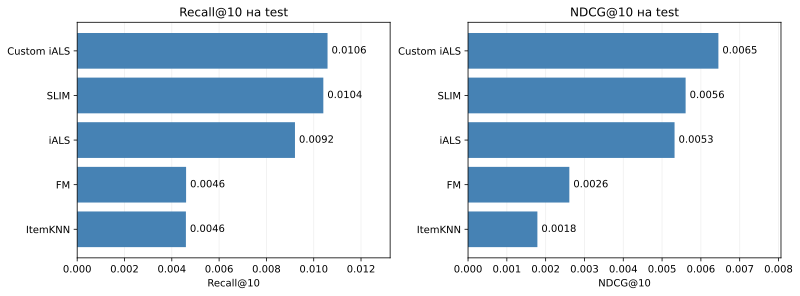

In [38]:
import matplotlib.pyplot as plt

comparison = (
    final_results.set_index("Модель")[["Recall@10", "NDCG@10"]]
    .sort_values("NDCG@10")
)

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained"
)

for ax, metric in zip(axes, comparison.columns):
    bars = ax.barh(
        comparison.index, comparison[metric], color="steelblue"
    )
    ax.bar_label(bars, fmt="%.4f", padding=4)
    ax.set(
        title=f"{metric} на test",
        xlabel=metric,
        xlim=(0, comparison[metric].max() * 1.25),
    )
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

plt.show()

## 6. Выводы

На выбранном временном разбиении лучшие результаты получил iALS с кастомным таргетом: Recall@10 = 0.010585, NDCG@10 = 0.006451. Оценка проводилась на 2085 пользователях среди 74 898 объектов обучающего каталога. Уже оценённые пользователем товары из рекомендаций исключались.

При одинаковых параметрах факторизации и confidence кастомный таргет дал примерно на 21% больший NDCG@10 и на 15% больший Recall@10 относительно базового iALS. Это демонстрирует полезность знакового нелинейного преобразования оценок в этом эксперименте.

На тестовой выборке SLIM занял второе место: Recall@10 составил 0.010407, NDCG@10 — 0.005607. Чтобы сократить время обучения, для каждого товара модель рассматривала только 30 объектов-кандидатов. Обучение итоговой модели и расчёт метрик заняли около 15 секунд, тогда как для кастомного iALS потребовалось около 166 секунд. Таким образом, SLIM оказался значительно быстрее при близком Recall@10.

FM и ItemKNN показали меньшую полноту рекомендаций: Recall@10 составил 0.004604 и 0.004596 соответственно. При практически одинаковом Recall FM получил больший NDCG@10: 0.002610 против 0.001787. Найденные релевантные товары в её рекомендациях в среднем получали более выгодные позиции.

Результаты характеризуют рекомендации для пользователей с накопленной историей: в выборку включались пользователи, оценившие минимум пять разных товаров в исходном train. Основная оценка охватывает известные модели товары. Из 5855 тестовых пар 1772 относятся к новым товарам и исключены из расчёта метрик. Это ограничивает применимость результатов к рекомендации новинок.

Для FM категории из единственного снимка метаданных приняты как статические свойства товаров. Это допущение следует учитывать при интерпретации временного эксперимента.

Абсолютное качество остаётся невысоким: даже лучший метод находит в top-10 в среднем около 1,06% доступных релевантных товаров пользователя. Кастомный iALS оказался лучшим среди проверенных вариантов, однако полученные рекомендации сохраняют значительный потенциал для улучшения.